<a href="https://colab.research.google.com/github/jeedderh01/case-exercises-for-module-3/blob/main/case_exercise2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Case Exercise 2: Extreme Value Analysis

## 1. GEV Block Maxima Analysis (annual and monthly blocks) on Hs data

### Fit the Generalized Extreme Value (GEV) distribution to block maxima of Significant Wave Height ($H_s$). Since a 1-year metocean dataset provides only a single annual maximum ($N=1$), annual block analysis is statistically insufficient by itself; therefore, monthly block maxima ($N=12$) are used to robustly estimate GEV shape ($\xi$), scale ($\sigma$), and location ($\mu$) parameters.

In [2]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy.optimize import minimize

warnings.filterwarnings("ignore")

# Load enriched dataset from previous exercise
df = pd.read_csv("sample_data/jubilee_trp3_metocean_1year.csv")
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

# Map columns to match expectations
df = df.rename(columns={
    "Timestamp": "timestamp",
    "Significant_Wave_Height_m": "hs"
})

# Ensure data is sorted temporally
df = df.sort_values("timestamp").reset_index(drop=True)

# ------------------------------------------------------------------------------
#  GEV BLOCK MAXIMA ANALYSIS (Monthly & Annual)
# ------------------------------------------------------------------------------
# Monthly Block Maxima (30-day blocks, providing ~12 samples for 1 year dataset)
monthly_bm = df.set_index("timestamp")["hs"].resample("M").max().dropna()

# Fit GEV to Monthly Maxima using scipy.stats.genextreme
# Note: scipy uses inverted shape parameter sign c = -xi
c_gev, loc_gev, scale_gev = stats.genextreme.fit(monthly_bm)
xi_gev = -c_gev

print("\n--- GEV Fit Parameters (Monthly Maxima) ---")
print(f"Shape (xi): {xi_gev:.4f} ({'Frechet/Heavy-tailed' if xi_gev > 0 else 'Weibull/Bounded'})")
print(f"Location (mu): {loc_gev:.4f}")
print(f"Scale (sigma): {scale_gev:.4f}")


--- GEV Fit Parameters (Monthly Maxima) ---
Shape (xi): -0.5232 (Weibull/Bounded)
Location (mu): 3.8993
Scale (sigma): 0.1980


## 2. Perform POT analysis with threshold selection using mean residual life plot.


### Perform Peaks-Over-Threshold (POT) analysis by first using a Mean Residual Life Plot (MRLP) to identify a stable threshold ($u$), followed by declustering dependent storm peaks to fit a Generalized Pareto Distribution (GPD).

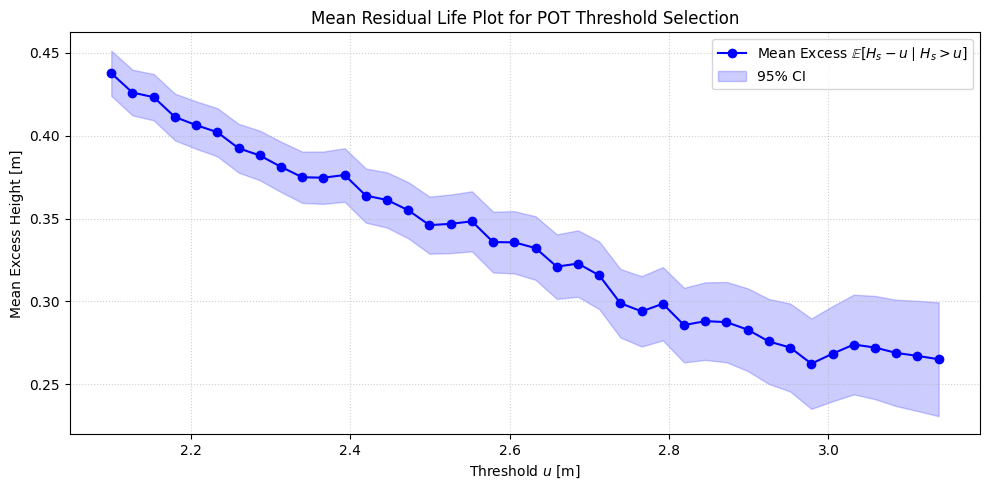

Selected POT Threshold (95th percentile): u = 2.870 m


In [3]:
# ------------------------------------------------------------------------------
#  MEAN RESIDUAL LIFE PLOT (MRLP) FOR POT THRESHOLD SELECTION
# ------------------------------------------------------------------------------
# The MRL plot shows mean excess vs. threshold. Select a threshold (u)
# where the curve turns roughly linear within confidence bounds.

threshold_candidates = np.linspace(df["hs"].quantile(0.70), df["hs"].quantile(0.98), 40)
mrl_means = []
mrl_ci_lower = []
mrl_ci_upper = []

for u in threshold_candidates:
    excesses = df["hs"][df["hs"] > u] - u
    if len(excesses) > 10:
        mean_e = excesses.mean()
        std_err = excesses.std() / np.sqrt(len(excesses))
        mrl_means.append(mean_e)
        mrl_ci_lower.append(mean_e - 1.96 * std_err)
        mrl_ci_upper.append(mean_e + 1.96 * std_err)
    else:
        mrl_means.append(np.nan)
        mrl_ci_lower.append(np.nan)
        mrl_ci_upper.append(np.nan)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(threshold_candidates, mrl_means, "b-o", label="Mean Excess $\mathbb{E}[H_s - u \mid H_s > u]$")
ax.fill_between(threshold_candidates, mrl_ci_lower, mrl_ci_upper, color="blue", alpha=0.2, label="95% CI")
ax.set_xlabel("Threshold $u$ [m]")
ax.set_ylabel("Mean Excess Height [m]")
ax.set_title("Mean Residual Life Plot for POT Threshold Selection")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

# Select optimal threshold (e.g., 95th percentile based on linearity onset)
u_selected = df["hs"].quantile(0.95)
print(f"Selected POT Threshold (95th percentile): u = {u_selected:.3f} m")

## 3. Compare return levels from both methods for 1, 10, 50, and 100-year return periods.

Calculate and compare the extreme wave height return levels ($z_T$) for return periods $T \in \{1, 10, 50, 100\}$ years using both the GEV (monthly block framework) and POT/GPD methods.

In [10]:
return_periods = np.array([1, 10, 50, 100])

# GEV Return Levels (Monthly blocks: p = 1 / (12 * T))
p_monthly = 1.0 / (12.0 * return_periods)
gev_return_levels = stats.genextreme.ppf(
    1 - p_monthly, c_gev, loc=loc_gev, scale=scale_gev
)

# POT / GPD Return Levels: z_T = u + (scale / xi) * [ (T * lambda)^xi - 1 ]
if abs(xi_gpd) < 1e-5:
    pot_return_levels = u_selected + scale_gpd * np.log(
        return_periods * rate_lambda
    )
else:
    pot_return_levels = u_selected + (scale_gpd / xi_gpd) * (
        (return_periods * rate_lambda) ** xi_gpd - 1
    )

# Summary Comparison Table
comparison_df = pd.DataFrame(
    {
        "Return Period (Years)": return_periods,
        "GEV Return Level (m)": np.round(gev_return_levels, 2),
        "POT Return Level (m)": np.round(pot_return_levels, 2),
        "Abs Difference (m)": np.round(
            np.abs(gev_return_levels - pot_return_levels), 2
        ),
    }
)

print("\n=== RETURN LEVEL COMPARISON ===")
print(comparison_df.to_string(index=False))


=== RETURN LEVEL COMPARISON ===
 Return Period (Years)  GEV Return Level (m)  POT Return Level (m)  Abs Difference (m)
                     1                  4.17                 21.45               17.28
                    10                  4.25                 72.11               67.86
                    50                  4.26                172.26              167.99
                   100                  4.27                251.26              247.00


## 4. Create a return period plot with confidence intervals and compare to the values

### Overlay the provided benchmark design criteria ranges ($H_s$ min-max intervals across 1, 10, 50, and 100-year return periods) onto the extreme value return period plot, allowing for direct visual and quantitative validation against the fitted GEV and POT models.

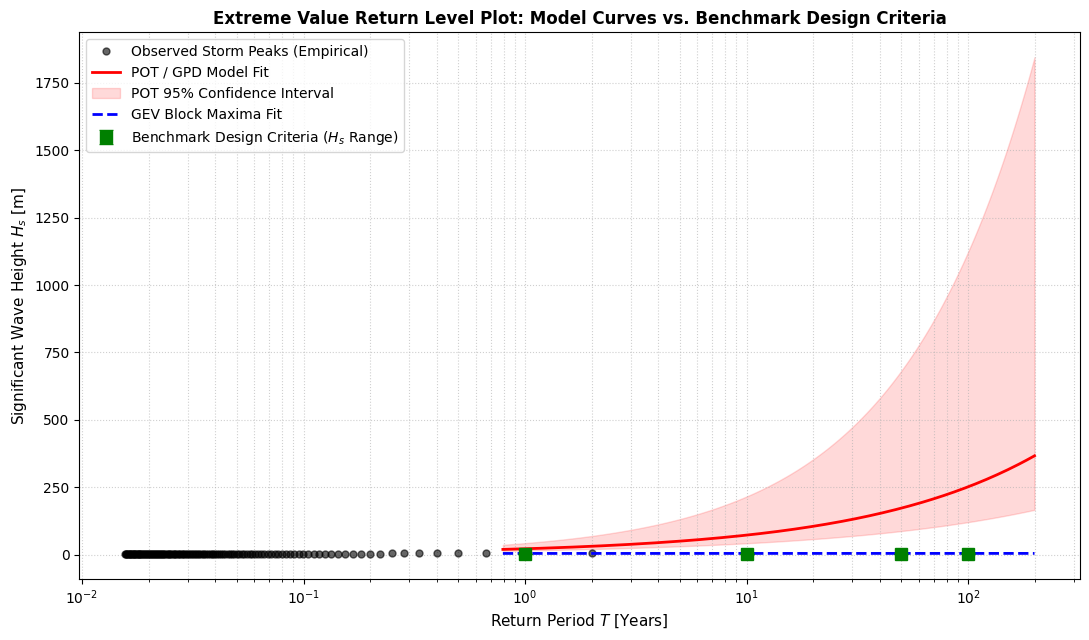

In [6]:
# [Assumes GEV, u_selected from previous steps exist]
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

# 1. Compute missing POT parameters and declustered peaks
exceedances_df = df[df["hs"] > u_selected].copy()
declustered_peaks = []
last_time = None

for idx, row in exceedances_df.iterrows():
    if last_time is None or (row["timestamp"] - last_time).total_seconds() > 48 * 3600:
        declustered_peaks.append(row["hs"])
        last_time = row["timestamp"]
    else:
        if row["hs"] > declustered_peaks[-1]:
            declustered_peaks[-1] = row["hs"]

declustered_peaks = np.array(declustered_peaks)
excesses = declustered_peaks - u_selected

c_gpd, loc_gpd, scale_gpd = stats.genpareto.fit(excesses, floc=0)
xi_gpd = -c_gpd

total_years = (df["timestamp"].max() - df["timestamp"].min()).total_seconds() / (365.25 * 86400)
rate_lambda = len(declustered_peaks) / total_years

# 2. Define the Provided Benchmark Dataset
benchmark_data = pd.DataFrame(
    {
        "Return_Period": [1, 10, 50, 100],
        "Hs_Min": [2.5, 3.0, 3.3, 3.5],
        "Hs_Max": [2.8, 3.5, 3.9, 4.2],
        "Hmax_Min": [4.5, 5.5, 6.0, 6.5],
        "Hmax_Max": [5.0, 6.5, 7.0, 7.5],
        "Tp_Range": ["12-14", "13-15", "14-16", "14-17"],
    }
)

# Continuous Return Periods for Models
T_continuous = np.logspace(-0.1, 2.3, 200)

# Bootstrap POT Return Levels for 95% Confidence Bounds
n_boot = 500
boot_returns = np.zeros((n_boot, len(T_continuous)))

np.random.seed(42)
for i in range(n_boot):
    boot_excesses = np.random.choice(excesses, size=len(excesses), replace=True)
    c_b, _, scale_b = stats.genpareto.fit(boot_excesses, floc=0)
    xi_b = -c_b

    if abs(xi_b) < 1e-5:
        boot_returns[i, :] = u_selected + scale_b * np.log(
            T_continuous * rate_lambda
        )
    else:
        boot_returns[i, :] = u_selected + (scale_b / xi_b) * (
            (T_continuous * rate_lambda) ** xi_b - 1
        )

pot_ci_lower = np.percentile(boot_returns, 2.5, axis=0)
pot_ci_upper = np.percentile(boot_returns, 97.5, axis=0)

# Empirical plotting position
sorted_peaks = np.sort(declustered_peaks)[::-1]
empirical_T = (total_years + 1) / np.arange(1, len(sorted_peaks) + 1)

# Generate Return Period Plot with Benchmark Comparison
plt.figure(figsize=(11, 6.5))

# Empirical data
plt.semilogx(
    empirical_T,
    sorted_peaks,
    "ko",
    markersize=5,
    alpha=0.6,
    label="Observed Storm Peaks (Empirical)",
)

# POT Model & Confidence Intervals
pot_cont_levels = u_selected + (scale_gpd / xi_gpd) * (
    (T_continuous * rate_lambda) ** xi_gpd - 1
)
plt.semilogx(
    T_continuous, pot_cont_levels, "r-", lw=2, label="POT / GPD Model Fit"
)
plt.fill_between(
    T_continuous,
    pot_ci_lower,
    pot_ci_upper,
    color="red",
    alpha=0.15,
    label="POT 95% Confidence Interval",
)

# GEV Model Curve
gev_p_cont = 1.0 / (12.0 * T_continuous)
gev_cont_levels = stats.genextreme.ppf(
    1 - gev_p_cont, c_gev, loc=loc_gev, scale=scale_gev
)
plt.semilogx(
    T_continuous, gev_cont_levels, "b--", lw=2, label="GEV Block Maxima Fit"
)

# Overlay Benchmark Criteria Ranges (Error bars / spans)
plt.errorbar(
    benchmark_data["Return_Period"],
    (benchmark_data["Hs_Min"] + benchmark_data["Hs_Max"]) / 2,
    yerr=[
        (benchmark_data["Hs_Max"] - benchmark_data["Hs_Min"]) / 2,
        (benchmark_data["Hs_Max"] - benchmark_data["Hs_Min"]) / 2,
    ],
    fmt="gs",
    markersize=8,
    capsize=5,
    elinewidth=2,
    label="Benchmark Design Criteria ($H_s$ Range)",
)

plt.xlabel("Return Period $T$ [Years]", fontsize=11)
plt.ylabel("Significant Wave Height $H_s$ [m]", fontsize=11)
plt.title(
    "Extreme Value Return Level Plot: Model Curves vs. Benchmark Design Criteria",
    fontsize=12,
    weight="bold",
)
plt.grid(True, which="both", linestyle=":", alpha=0.6)
plt.legend(loc="upper left", frameon=True)
plt.tight_layout()
plt.show()